# ДЗ №1 СУНЦ МГУ - Numpy practice

**Среда:** Python 3.14.7. Локальные модули `functions.py` и `functions_vectorized.py` повторно импортируются при каждом запуске ячейки с решением.


### Туториальные задачи
__(9 баллов)__

Ниже приведены задачи на работу с numpy-массивами. Для каждой из задач нужно привести 2 реализации: одна без использования numpy (cчитайте, что там, где на входе или выходе должны быть numpy array, будут просто списки), а вторая полностью векторизованная (без использования питоновских циклов/map/list comprehension). Невекторизованная реализация каждой из задач оценивается в __0.5 балла__, векторизованная – в __1 балл__.

Реализации без использования векторизации нужно записать в файл functions.py, а векторизованные &mdash; в файл functions_vectorized.py

Для каждой задачи, приведённой ниже сравните скорость работы невекторизованной и векторизованной реализации. С помощью пакета matplotlib постройте графики времени работы в зависимости от размера данных. __Графики должны выглядеть опрятно!__ То есть должны быть подписаны оси, названия графиков, и т.д. Например, ниже представлены хороший и плохой графики:

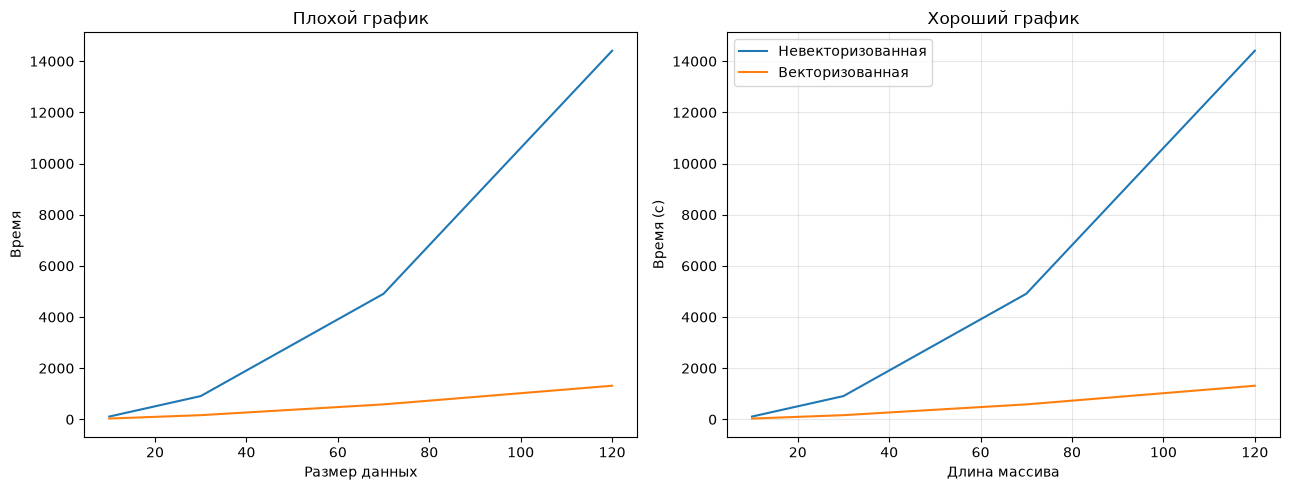

In [4]:
from importlib import reload

import matplotlib.pyplot as plt
import numpy as np

import functions
import functions_vectorized

%matplotlib inline


def reload_solution_modules():
    """Reload the two local solution modules after their files change."""
    reload(functions)
    reload(functions_vectorized)


data_size = np.array([10, 30, 70, 120])
time_non_vectorized = data_size**2 + 10
time_vectorized = data_size**1.5

figure, (axis_bad, axis_good) = plt.subplots(1, 2, figsize=(13, 5))

axis_bad.plot(data_size, time_non_vectorized)
axis_bad.plot(data_size, time_vectorized)
axis_bad.set_title("Плохой график")
axis_bad.set_xlabel("Размер данных")
axis_bad.set_ylabel("Время")

axis_good.plot(data_size, time_non_vectorized, label="Невекторизованная")
axis_good.plot(data_size, time_vectorized, label="Векторизованная")
axis_good.set_title("Хороший график")
axis_good.set_xlabel("Длина массива")
axis_good.set_ylabel("Время (с)")
axis_good.grid(True, alpha=0.3)
axis_good.legend()

figure.tight_layout()
plt.show()


* __Задача 1__: Подсчитать произведение ненулевых элементов на диагонали прямоугольной матрицы.  
 Например, для X = np.array([[1, 0, 1], [2, 0, 2], [3, 0, 3], [4, 4, 4]]) ответ – 3.

C:\Users\vfedy\Downloads\dz1\functions.py:6: RuntimeWarning: overflow encountered in scalar multiply
  result *= X[i][i]


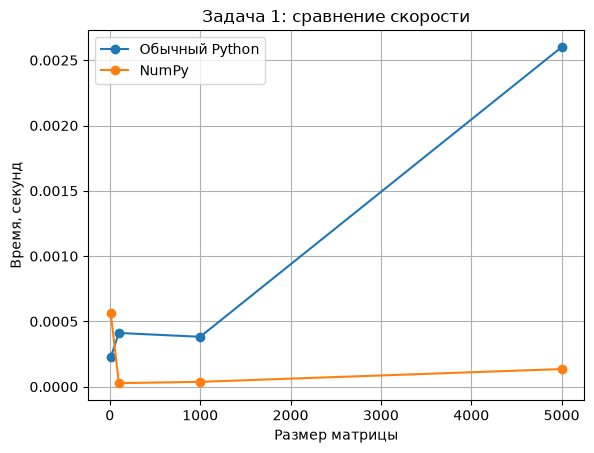

In [5]:
reload_solution_modules()

import time

sizes = [10, 100, 1000, 5000]

time_normal = []
time_vectorized = []

for n in sizes:
    X = np.random.randint(0, 5, size=(n, n))

    start = time.perf_counter()
    functions.prod_non_zero_diag(X)
    end = time.perf_counter()
    time_normal.append(end - start)

    start = time.perf_counter()
    functions_vectorized.prod_non_zero_diag(X)
    end = time.perf_counter()
    time_vectorized.append(end - start)

plt.plot(sizes, time_normal, marker='o', label='Обычный Python')
plt.plot(sizes, time_vectorized, marker='o', label='NumPy')

plt.xlabel('Размер матрицы')
plt.ylabel('Время, секунд')
plt.title('Задача 1: сравнение скорости')
plt.legend()
plt.grid()

plt.show()


 
 
* __Задача 2__: Даны два вектора x и y. Проверить, задают ли они одно и то же мультимножество.  
  Например, для x = np.array([1, 2, 2, 4]), y = np.array([4, 2, 1, 2]) ответ – True.
  
  


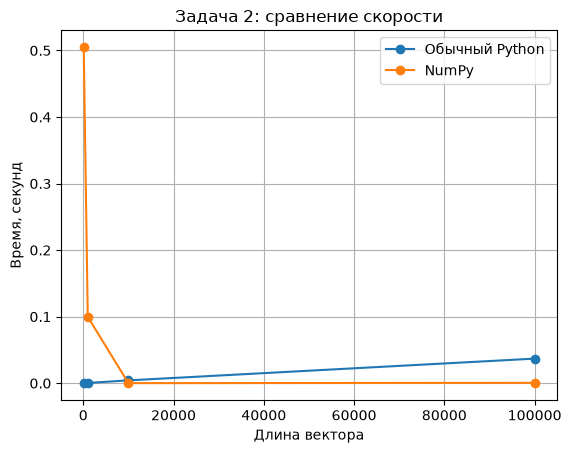

In [6]:
reload_solution_modules()

import time

sizes = [100, 1000, 10000, 100000]

time_normal = []
time_vectorized = []

for n in sizes:
    x = np.random.randint(0, 100, size=n)

    y = x.copy()
    np.random.shuffle(y)

    start = time.perf_counter()
    functions.are_multisets_equal(x, y)
    end = time.perf_counter()
    time_normal.append(end - start)

    start = time.perf_counter()
    functions_vectorized.are_multisets_equal(x, y)
    end = time.perf_counter()
    time_vectorized.append(end - start)

plt.plot(sizes, time_normal, marker='o', label='Обычный Python')
plt.plot(sizes, time_vectorized, marker='o', label='NumPy')

plt.xlabel('Длина вектора')
plt.ylabel('Время, секунд')
plt.title('Задача 2: сравнение скорости')
plt.legend()
plt.grid()

plt.show()


* __Задача 3__: Найти максимальный элемент в векторе x среди элементов, перед которыми стоит нулевой.  
 Например, для x = np.array([6, 2, 0, 3, 0, 0, 5, 7, 0]) ответ – 5.

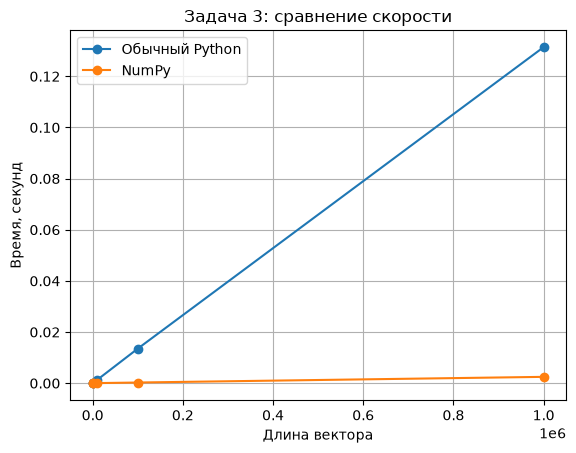

In [7]:
reload_solution_modules()

import time

sizes = [100, 1000, 10000, 100000, 1000000]

time_normal = []
time_vectorized = []

for n in sizes:
    x = np.random.randint(0, 10, size=n)

    start = time.perf_counter()
    functions.max_after_zero(x)
    end = time.perf_counter()
    time_normal.append(end - start)

    start = time.perf_counter()
    functions_vectorized.max_after_zero(x)
    end = time.perf_counter()
    time_vectorized.append(end - start)

plt.plot(sizes, time_normal, marker='o', label='Обычный Python')
plt.plot(sizes, time_vectorized, marker='o', label='NumPy')

plt.xlabel('Длина вектора')
plt.ylabel('Время, секунд')
plt.title('Задача 3: сравнение скорости')
plt.legend()
plt.grid()

plt.show()

 
 
* __Задача 4__: Дан трёхмерный массив, содержащий изображение, размера (height, width, numChannels), а также вектор длины numChannels. Сложить каналы изображения с указанными весами, и вернуть результат в виде матрицы размера (height, width). В ноутбуке приведите пример работы функции – преобразуйте цветное изображение в оттенки серого, использовав коэффициенты np.array([0.299, 0.587, 0.114]). Считать реальное изображение можно с помощью `PIL.Image.open` из пакета Pillow: `img = np.asarray(Image.open(path).convert("RGB"))`. Устаревшая функция `scipy.misc.imread` удалена из современных версий SciPy.


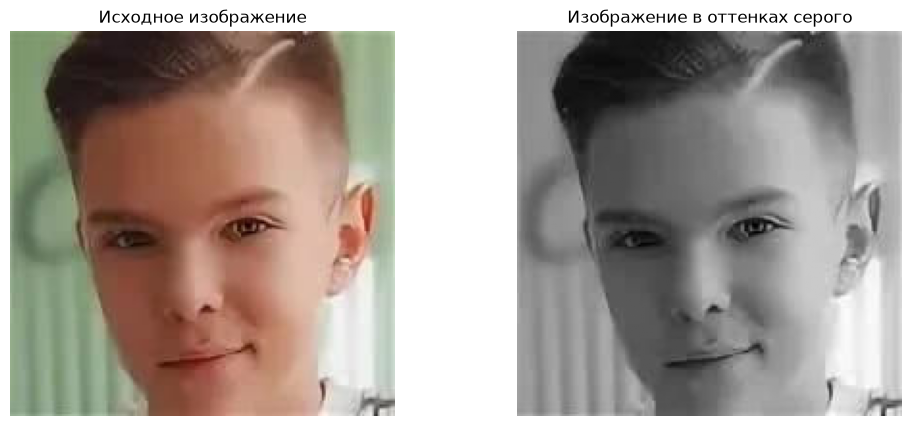

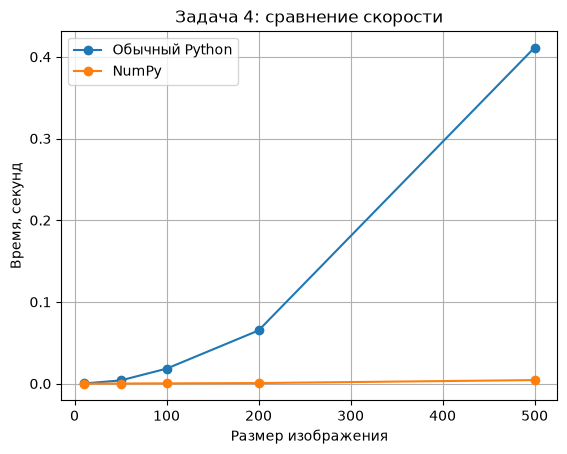

In [8]:
reload_solution_modules()

import time

img = plt.imread("dzML.jpg")

coefs = np.array([0.299, 0.587, 0.114])

gray_img = functions_vectorized.convert_image(img, coefs)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Исходное изображение")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray_img, cmap="gray")
plt.title("Изображение в оттенках серого")
plt.axis("off")

plt.show()

sizes = [10, 50, 100, 200, 500]

time_normal = []
time_vectorized = []

for n in sizes:

    test_img = np.random.randint(
        0, 256,
        size=(n, n, 3)
    )

    start = time.perf_counter()

    functions.convert_image(
        test_img,
        coefs
    )

    end = time.perf_counter()

    time_normal.append(
        end - start
    )

    start = time.perf_counter()

    functions_vectorized.convert_image(
        test_img,
        coefs
    )

    end = time.perf_counter()

    time_vectorized.append(
        end - start
    )


plt.plot(
    sizes,
    time_normal,
    marker="o",
    label="Обычный Python"
)

plt.plot(
    sizes,
    time_vectorized,
    marker="o",
    label="NumPy"
)

plt.xlabel("Размер изображения")
plt.ylabel("Время, секунд")
plt.title("Задача 4: сравнение скорости")

plt.legend()
plt.grid()

plt.show()

* __Задача 5__: Реализовать кодирование длин серий (Run-length encoding). Для некоторого вектора x необходимо вернуть кортеж из двух векторов одинаковой длины. Первый содержит числа, а второй - сколько раз их нужно повторить.  
 Например, для x = np.array([2, 2, 2, 3, 3, 3, 5]) ответ – (np.array([2, 3, 5]), np.array([3, 3, 1])).

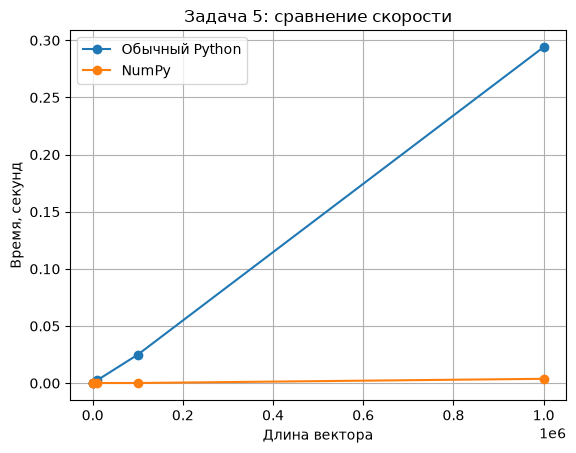

In [19]:
reload_solution_modules()

import time

sizes = [100, 1000, 10000, 100000, 1000000]

time_normal = []
time_vectorized = []

for n in sizes:
    x = np.repeat(
        np.random.randint(0, 100, size=n // 10),
        10
    )

    start = time.perf_counter()
    functions.run_length_encoding(x)
    end = time.perf_counter()
    time_normal.append(end - start)

    start = time.perf_counter()
    functions_vectorized.run_length_encoding(x)
    end = time.perf_counter()
    time_vectorized.append(end - start)

plt.plot(
    sizes,
    time_normal,
    marker="o",
    label="Обычный Python"
)

plt.plot(
    sizes,
    time_vectorized,
    marker="o",
    label="NumPy"
)

plt.xlabel("Длина вектора")
plt.ylabel("Время, секунд")
plt.title("Задача 5: сравнение скорости")

plt.legend()
plt.grid()

plt.show()

 
 
* __Задача 6__: Даны две выборки объектов - X и Y. Вычислить матрицу евклидовых расстояний между объектами. Дополнительно сравните с функцией scipy.spatial.distance.cdist по скорости работы (сравнения приведите ниже в ноутбуке).

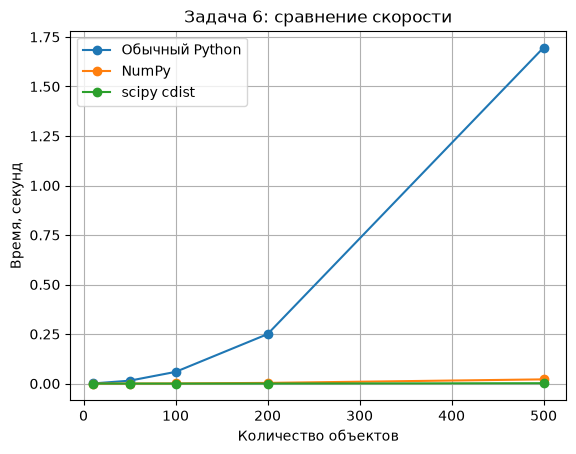

In [21]:
reload_solution_modules()

import time
from scipy.spatial.distance import cdist

sizes = [10, 50, 100, 200, 500]

time_normal = []
time_vectorized = []
time_cdist = []

for n in sizes:
    x = np.random.rand(n, 10)
    y = np.random.rand(n, 10)

    start = time.perf_counter()
    functions.pairwise_distance(x, y)
    end = time.perf_counter()
    time_normal.append(end - start)

    start = time.perf_counter()
    functions_vectorized.pairwise_distance(x, y)
    end = time.perf_counter()
    time_vectorized.append(end - start)

    start = time.perf_counter()
    cdist(x, y, metric="euclidean")
    end = time.perf_counter()
    time_cdist.append(end - start)

plt.plot(
    sizes,
    time_normal,
    marker="o",
    label="Обычный Python"
)

plt.plot(
    sizes,
    time_vectorized,
    marker="o",
    label="NumPy"
)

plt.plot(
    sizes,
    time_cdist,
    marker="o",
    label="scipy cdist"
)

plt.xlabel("Количество объектов")
plt.ylabel("Время, секунд")
plt.title("Задача 6: сравнение скорости")

plt.legend()
plt.grid()

plt.show()

### Туториал по Markdown

__(1 балл)__

Напишите краткий (а в данной домашке ещё и почти бесмысленный) отчёт с использованием 4-5 различных вариантов разметки/выделения текста.

# Отчёт по работе с NumPy

## Цель работы

В данной работе были рассмотрены базовые операции с массивами NumPy и проведено сравнение обычных реализаций на Python с векторизованными решениями.

### Выполненные задачи

- произведение ненулевых элементов главной диагонали;
- сравнение мультимножеств;
- поиск максимального элемента после нуля;
- преобразование RGB-изображения в оттенки серого;
- Run-Length Encoding;
- вычисление попарных евклидовых расстояний.

## Наблюдения

В большинстве задач векторизованные решения на NumPy работают быстрее обычных реализаций с циклами.

Особенно заметна разница на больших объёмах данных.

> Векторизация позволяет выполнять операции сразу над целыми массивами, не перебирая элементы вручную в Python.

Для шестой задачи дополнительно использовалась функция `scipy.spatial.distance.cdist`.

Она показала очень высокую скорость работы и оказалась быстрее или сопоставима с собственной NumPy-реализацией.

## Итог

**NumPy значительно упрощает работу с числовыми данными и позволяет писать более короткий и быстрый код.**

Также я познакомился с:

1. индексированием массивов;
2. булевыми масками;
3. broadcasting;
4. функциями `np.sum`, `np.max`, `np.sort`, `np.diag`;
5. измерением времени выполнения кода;
6. построением графиков с помощью `matplotlib`.

---

Итоговый вывод: чем больше объём данных, тем заметнее преимущество векторизованных операций.